# Un complemento de escala y nivel para la prueba PLA

**Pregunta:** Un modelo de riesgo cuya volatilidad tiene 20 días de atraso aprueba la prueba de atribución de P&L del FRTB en todos
los años simulados; ¿pueden tres estadísticos calculados sobre los mismos 250 días de P&L hipotético y teórico de riesgo detectarlo,
con una tasa de falsas alarmas de 1 %?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 01 a 07 de este tema y la página del caso C13 (la mesa, su generador y las zonas PLA)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- decir por qué la prueba PLA, una correlación de Spearman y una distancia de Kolmogorov-Smirnov entre el P&L hipotético de la mesa
  (HPL) y el P&L del modelo de riesgo (RTPL), no puede ver un modelo que lee los factores correctos con una volatilidad de semanas
  de atraso;
- calcular sobre un año de mesa los tres estadísticos que el producto propone junto a la zona, y leer cada uno;
- calibrar sus umbrales sobre una nula simulada con el motor, y medir su potencia sobre el modelo rezagado y sus falsas alarmas sobre
  mesas exactas reservadas;
- leer la medición versionada del producto sobre 1.000 replicaciones y decir qué afirma el complemento y qué no.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca
instala nada por sí mismo. La celda siguiente importa lo que usa el notebook e imprime las versiones.

In [1]:
# Importar las herramientas, poner el generador del caso en la ruta e imprimir las versiones con que corren
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.market import frtb
from riskvalidation.market import pla_complement as pc

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c13 import generator

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C13 es una mesa de trading sintética cuya verdad se conoce: el generador `pipeline.cases.c13.generator` sortea un año de
retornos diarios de dos factores de riesgo correlacionados bajo una volatilidad que se desplaza, el HPL de la mesa a partir de ellos
y el RTPL que calcula un modelo de riesgo. Cada variante planta una deficiencia en el modelo. Este notebook usa dos: el modelo exacto y
el modelo que lee una volatilidad de 20 días de atraso (`stale-volatility`), y los documentos versionados de ambos, que guardan la
medición propia del producto sobre 1.000 replicaciones. Los datos son generados, licencia MIT, y los documentos están versionados en
`data/derived/C13/`.

In [2]:
# Leer los documentos versionados del caso C13: el modelo exacto y el modelo con una volatilidad de 20 días de atraso
C13 = ROOT / "data" / "derived" / "C13"
docs = {v: json.loads((C13 / f"{v}.json").read_text(encoding="utf-8")) for v in ("none", "stale-volatility")}
stale_doc = docs["stale-volatility"]["outputs"]
print("riskvalidation", docs["none"]["provenance"]["riskvalidation_version"])
for p in stale_doc["known_deficiency"]["parameters"]:
    print(p["name"], p["value"], p["unit"])
print("replicaciones versionadas:", stale_doc["pla_complement"]["n_replications"])


riskvalidation 1.1.0
vol_lag_days 20.0 days
replicaciones versionadas: 1000


## Método

La prueba PLA compara las dos series de P&L por rango (Spearman) y por distribución (Kolmogorov-Smirnov), y una mesa es verde cuando
ambas están cerca. Las dos son ciegas a *cuándo* se mueve la escala: un modelo que aplica los choques correctos con una volatilidad
antigua ordena los días casi como la mesa y, en un año, saca P&L de casi la misma distribución. El complemento agrega tres
estadísticos sobre los mismos 250 días, calculados por `riskvalidation.market.pla_complement` del motor:

1. la regresión de Mincer-Zarnowitz $\mathrm{HPL}_t = a + b\,\mathrm{RTPL}_t + e_t$ y la prueba de Wald de $(a, b) = (0, 1)$ con la
   covarianza HC3, que ve un modelo mal escalado o desplazado;
2. la correlación de Spearman de $|\mathrm{HPL}|$ y $|\mathrm{RTPL}|$, que ve un modelo que juzga mal el tamaño del movimiento del día;
3. la correlación de Spearman de las medias móviles de 20 días de $|\mathrm{HPL}|$ y $|\mathrm{RTPL}|$: el choque diario lo comparten
   ambas series, así que la media móvil lo elimina y deja las dos escalas, y un modelo cuya volatilidad tiene $L$ días de atraso mueve
   su escala $L$ días tarde.

La primera celda calcula la zona y los tres estadísticos sobre un año de mesa de cada modelo.

In [3]:
# Un año de mesa de cada modelo desde el generador del caso: la zona regulatoria y los tres estadísticos del complemento
desks = {"exact": generator.replicate("none", 0, 13), "stale": generator.replicate("stale-volatility", 0, 13)}
for name, d in desks.items():
    zone = frtb.pla_zone(frtb.pla_spearman(d.hpl, d.rtpl), frtb.pla_ks(d.hpl, d.rtpl))
    s = pc.pla_complement_statistics(d.hpl, d.rtpl, 20)
    mz = f"Wald {s.wald:6.2f} (p {s.p_value:.4f}), slope {s.slope:.3f}"
    print(f"{name:6s} zone {zone:6s} | {mz} | Spearman |P&L| {s.spearman_abs:.4f} | rolling {s.spearman_roll:.4f}")


exact  zone green  | Wald   0.55 (p 0.7599), slope 0.997 | Spearman |P&L| 0.9465 | rolling 0.9960
stale  zone green  | Wald  10.04 (p 0.0066), slope 0.950 | Spearman |P&L| 0.9035 | rolling 0.8184


Las dos mesas son verdes: la zona regulatoria no las separa. Los tres estadísticos sí, en distinta medida. En la mesa exacta el
estadístico de Wald es 0,55 con una pendiente de 0,997, y las dos correlaciones son 0,9465 y 0,9960. En la mesa rezagada la pendiente
baja a 0,950 y el estadístico de Wald sube a 10,04, la correlación del P&L absoluto baja a 0,9035 y la móvil es la que más baja, a
0,8184. La figura muestra por qué el estadístico móvil es el más agudo de los tres.

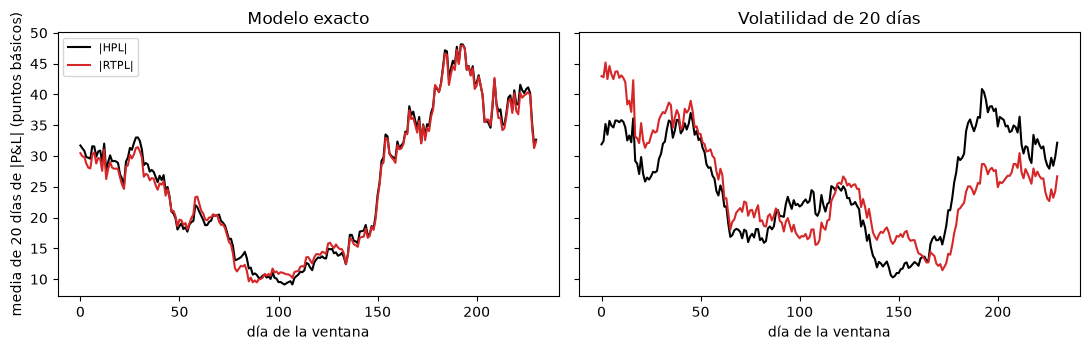

In [4]:
# Dibujar las medias móviles de 20 días de |HPL| y |RTPL| en ambas mesas: la escala que muestra cada modelo y la debida
window = np.ones(20) / 20
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, d) in zip(axes, desks.items()):
    ax.plot(1e4 * np.convolve(np.abs(d.hpl), window, mode="valid"), color="black", label="|HPL|")
    ax.plot(1e4 * np.convolve(np.abs(d.rtpl), window, mode="valid"), color="tab:red", label="|RTPL|")
    ax.set_title("Modelo exacto" if name == "exact" else "Volatilidad de 20 días")
    ax.set_xlabel("día de la ventana")
axes[0].set_ylabel("media de 20 días de |P&L| (puntos básicos)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


A la izquierda las dos medias móviles de la mesa exacta quedan una sobre otra durante toda la ventana: la escala del modelo es
la escala de la mesa. A la derecha la línea roja sigue a la negra con un retraso de unas cuatro semanas, subiendo después de que la
volatilidad de la mesa ya subió y bajando después de que ya bajó. Los rangos diarios de las dos series de P&L siguen de acuerdo, por
eso la zona sigue verde, pero las escalas discrepan durante semanas, y esa discrepancia es lo que mide la correlación móvil.

Un estadístico necesita un umbral, y ninguno de los tres tiene una distribución de manual bajo el modelo exacto: las series de
P&L son heterocedásticas y las medias móviles se traslapan. El motor calibra cada umbral sobre una nula simulada, el cuantil del
estadístico sobre años de mesa del modelo exacto, con un tamaño declarado. El complemento se lee con un tamaño de 1 % para la unión de
los tres estadísticos, que la corrección de Bonferroni reparte en un tercio de punto porcentual cada uno; la celda siguiente imprime
también los umbrales al 1 % de cada estadístico solo. La nula se sortea con tres semillas que la corrida versionada no usa, así que lo
que sigue está fuera de muestra.

In [5]:
# Calibrar los umbrales con 300 años de mesa del modelo exacto, bajo tres semillas que la corrida versionada no usa
null = []
for case_seed in (5013, 5014, 5015):
    for i in range(100):
        d = generator.replicate("none", i, case_seed)
        null.append(pc.pla_complement_statistics(d.hpl, d.rtpl, 20))
union = pc.pla_complement_calibrate(null, 0.01, "bonferroni")
each = pc.pla_complement_calibrate(null, 0.01, "none")
for label, th in (("unión de las tres al 1%", union), ("cada estadístico al 1%", each)):
    rule = f"Wald > {th.wald:.2f} | Spearman |P&L| < {th.spearman_abs:.4f} | rolling < {th.spearman_roll:.4f}"
    print(f"{label:28s} {rule}")


unión de las tres al 1%      Wald > 11.51 | Spearman |P&L| < 0.9346 | rolling < 0.9324
cada estadístico al 1%       Wald > 11.12 | Spearman |P&L| < 0.9382 | rolling < 0.9602


## Comparación

El método frente al que se pone el complemento es la propia prueba PLA regulatoria: sus dos estadísticos y la zona de MAR32 (verde,
ámbar o roja según la correlación de Spearman y la distancia KS), la única prueba que el estándar aplica a la atribución de una mesa.
La celda siguiente corre la prueba y el complemento sobre los mismos 200 años de mesa del modelo con volatilidad rezagada, con los
umbrales recién calibrados.

In [6]:
# La zona regulatoria y el complemento sobre los mismos 200 años de mesa del modelo con volatilidad rezagada
stale_stats, stale_zone = [], []
for i in range(200):
    d = generator.replicate("stale-volatility", i, 13)
    stale_stats.append(pc.pla_complement_statistics(d.hpl, d.rtpl, 20))
    stale_zone.append(frtb.pla_zone(frtb.pla_spearman(d.hpl, d.rtpl), frtb.pla_ks(d.hpl, d.rtpl)))
decisions = [pc.pla_complement_decide(s, union) for s in stale_stats]
power = {
    "PLA": np.mean([z != "green" for z in stale_zone]),
    "Wald": np.mean([x.flag_wald for x in decisions]),
    "Spearman |P&L|": np.mean([x.flag_spearman_abs for x in decisions]),
    "rolling": np.mean([x.flag_spearman_roll for x in decisions]),
    "complemento (cualquiera)": np.mean([x.flagged for x in decisions]),
}
for name, value in power.items():
    print(f"{name:28s} {value:.3f}")


PLA                          0.000
Wald                         0.115
Spearman |P&L|               0.730
rolling                      0.990
complemento (cualquiera)     0.995


La zona no marca ninguno de los 200 años de mesa rezagados: con este generador la prueba regulatoria no puede ver una volatilidad
de 20 días de atraso. El complemento marca el 99,5 % de ellos. La mayor parte viene solo de la correlación móvil (99,0 %); la
correlación del P&L absoluto marca el 73,0 % y la prueba de Wald el 11,5 %, porque una volatilidad rezagada deja la pendiente media
cerca de uno. La celda siguiente pregunta qué tan antigua debe ser la volatilidad para que el complemento la vea, con 100 años de mesa
en cada uno de cuatro rezagos.

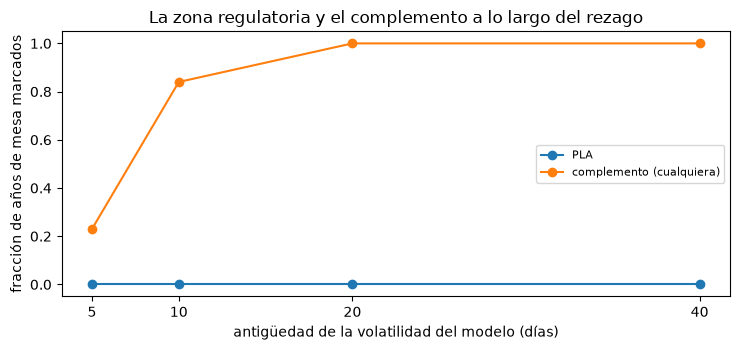

5: 0.23, 10: 0.84, 20: 1.00, 40: 1.00


In [7]:
# La escalera de rezagos: 100 años de mesa por antigüedad de la volatilidad, la zona regulatoria frente al complemento
lags = (5, 10, 20, 40)
ladder = {"PLA": [], "complemento (cualquiera)": []}
for lag in lags:
    flags_pla, flags_any = [], []
    for i in range(100):
        d = generator.replicate("stale-volatility", i, 13, vol_lag_days=float(lag))
        flags_pla.append(frtb.pla_zone(frtb.pla_spearman(d.hpl, d.rtpl), frtb.pla_ks(d.hpl, d.rtpl)) != "green")
        flags_any.append(pc.pla_complement_decide(pc.pla_complement_statistics(d.hpl, d.rtpl, 20), union).flagged)
    ladder["PLA"].append(np.mean(flags_pla))
    ladder["complemento (cualquiera)"].append(np.mean(flags_any))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, values in ladder.items():
    ax.plot(lags, values, marker="o", label=name)
ax.set_xticks(lags)
ax.set_xlabel("antigüedad de la volatilidad del modelo (días)")
ax.set_ylabel("fracción de años de mesa marcados")
ax.set_title("La zona regulatoria y el complemento a lo largo del rezago")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(", ".join(f"{lag}: {a:.2f}" for lag, a in zip(lags, ladder["complemento (cualquiera)"])))


La zona se queda en cero a lo largo de toda la escalera, desde un rezago de 5 días hasta uno de 40. El complemento sube con el
rezago: marca 0,23 de los años de mesa con 5 días, 0,84 con 10 días y todos desde 20 días. Una volatilidad de una semana de atraso es
difícil de distinguir del ruido de un año de datos, y el complemento lo dice en lugar de afirmarlo; desde las dos semanas separa el
modelo rezagado del exacto, donde la zona regulatoria nunca lo hace.

## Evidencia

La afirmación, fijada en el SDD antes de cualquier corrida: con un tamaño de a lo sumo 1 %, el complemento marca el modelo con una
volatilidad de 20 días de atraso en al menos 30 % de las replicaciones, y la afirmación se refuta bajo 10 %. Una tasa de marcas no
significa nada sin las falsas alarmas que la compran, así que la celda siguiente corre el complemento, con los mismos umbrales, sobre
300 años de mesa exactos con la semilla del caso (ninguno en la nula) y pone las dos tasas lado a lado para cada estadístico y para la
unión.

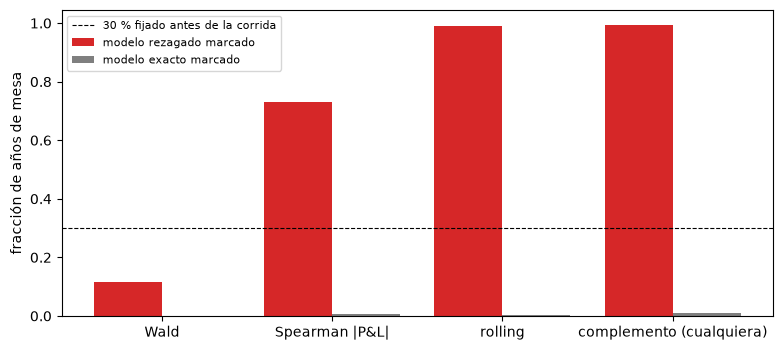

Wald                         modelo rezagado marcado 0.115 | modelo exacto marcado 0.000
Spearman |P&L|               modelo rezagado marcado 0.730 | modelo exacto marcado 0.007
rolling                      modelo rezagado marcado 0.990 | modelo exacto marcado 0.003
complemento (cualquiera)     modelo rezagado marcado 0.995 | modelo exacto marcado 0.010


In [8]:
# Medir la afirmación: las falsas alarmas en 300 mesas exactas reservadas junto a las marcas de las mesas rezagadas
held_desks = [generator.replicate("none", i, 13) for i in range(300)]
held = [pc.pla_complement_statistics(d.hpl, d.rtpl, 20) for d in held_desks]
held_dec = [pc.pla_complement_decide(s, union) for s in held]
alarms = {
    "Wald": np.mean([x.flag_wald for x in held_dec]),
    "Spearman |P&L|": np.mean([x.flag_spearman_abs for x in held_dec]),
    "rolling": np.mean([x.flag_spearman_roll for x in held_dec]),
    "complemento (cualquiera)": np.mean([x.flagged for x in held_dec]),
}
names = list(alarms)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, [power[n] for n in names], 0.4, label="modelo rezagado marcado", color="tab:red")
ax.bar(x + 0.2, [alarms[n] for n in names], 0.4, label="modelo exacto marcado", color="tab:gray")
ax.axhline(0.30, color="black", linestyle="--", linewidth=0.8, label="30 % fijado antes de la corrida")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("fracción de años de mesa")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
power_label, alarms_label = "modelo rezagado marcado", "modelo exacto marcado"
for n in names:
    print(f"{n:28s} {power_label} {power[n]:.3f} | {alarms_label} {alarms[n]:.3f}")


Toda barra gris queda cerca o bajo el tamaño nominal: la unión levanta 0,010 falsas alarmas en las mesas exactas, la prueba de
Wald ninguna, la correlación absoluta 0,007 y la móvil 0,003. Toda barra roja salvo la de la prueba de Wald queda sobre el 30 %
discontinuo que pide la afirmación, y la de la unión, con 0,995, queda muy por encima. La afirmación se cumple en esta corrida de 200
años de mesa rezagados y 300 exactos, y nada se ajustó para lograrlo: la ventana, el tamaño y la corrección se fijaron antes de sortear
la nula. La corrida propia del producto es mayor.

In [9]:
# La medición versionada del producto: 1.000 replicaciones con la semilla del caso, la nula con 10.000 años de mesa
block = stale_doc["pla_complement"]
fam = block["flags"]["family"]["any"]
union_label, alarms_label = "unión de las tres al 1%", "modelo exacto marcado"
print(f"{union_label}: {fam['k']} / {fam['n']} = {fam['rate']:.3f} ({fam['ci_low']:.3f} to {fam['ci_high']:.3f})")
for key, row in block["flags"]["per_statistic"].items():
    print(f"  {key:14s} {row['rate']:.3f}")
held_out = docs["none"]["outputs"]["pla_complement"]["flags"]["family"]["any"]
print(f"{alarms_label}: {held_out['k']} / {held_out['n']} = {held_out['rate']:.3f}")


unión de las tres al 1%: 999 / 1000 = 0.999 (0.994 to 1.000)
  wald           0.142
  spearman_abs   0.767
  spearman_roll  0.999
  any            1.000
modelo exacto marcado: 9 / 1000 = 0.009


La medición versionada marca 999 de 1.000 años de mesa rezagados para la unión al 1 %, un intervalo de 0,994 a 0,9998, con
umbrales calibrados sobre 10.000 años de mesa nulos, y 9 falsas alarmas en 1.000 exactos (0,009). La corrida más pequeña de este
notebook coincide con ella dentro de su propio error muestral. Lo que el complemento no afirma: no tiene valor regulatorio, se agrega
junto a la zona y nunca la reemplaza, y está calibrado sobre este generador, así que una mesa con otro proceso de P&L necesita su
propia nula.

## Resultados

**Respuesta:** Sí. Sobre años de mesa del generador del caso la zona PLA regulatoria marca el modelo con una volatilidad de 20 días de
atraso en ninguno de 200 años de mesa, mientras el complemento, calibrado al 1 % para la unión de sus tres estadísticos, marca 0,995 de
ellos y levanta 0,010 falsas alarmas en 300 años de mesa exactos reservados; la correlación móvil del P&L absoluto hace casi todo el
trabajo. La medición versionada del producto sobre 1.000 replicaciones da 0,999 contra 0,009. Bajo un rezago de unos diez días el
complemento pierde potencia (0,23 con 5 días), que es el límite de un año de datos.

## Resumen

- La zona PLA ordena y compara distribuciones, así que no puede ver un modelo cuya volatilidad va atrasada respecto de la de la mesa:
  ninguno de 200 años de mesa rezagados fue ámbar o rojo.
- La correlación móvil del P&L absoluto sigue la escala a lo largo de 20 días y marca sola 0,990 de los años de mesa rezagados; la
  unión de los tres estadísticos marca 0,995.
- Los umbrales salen de una nula simulada del modelo exacto con un tamaño declarado, y las falsas alarmas en mesas exactas reservadas
  quedan cerca de él (0,010 para la unión).
- El complemento es información junto a la zona, calibrada sobre este generador, sin valor regulatorio.

## Referencias

- Basel Committee on Banking Supervision (2019), Minimum capital requirements for market risk, MAR32 (la prueba de atribución de P&L). https://www.bis.org/bcbs/publ/d457.htm
- Mincer, J. y Zarnowitz, V. (1969), The evaluation of economic forecasts, en J. Mincer (ed.), Economic Forecasts and Expectations, NBER.
- MacKinnon, J. G. y White, H. (1985), Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties, Journal of Econometrics 29(3), 305-325.
- riskvalidation 1.1.0, `market.pla_complement` y su página. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/market/09_pla-complement.md